Total participants: 100
Total observations: 10000
Trials per participant: 100
Trials per pair per participant: 50

Saved CSV: /Users/yperez3/simu_learner_100_paired_parameters.csv
Total observations saved: 10000
First trial: 1
Last trial: 100
First participant: 1
Last participant: 100
Trial count check complete.


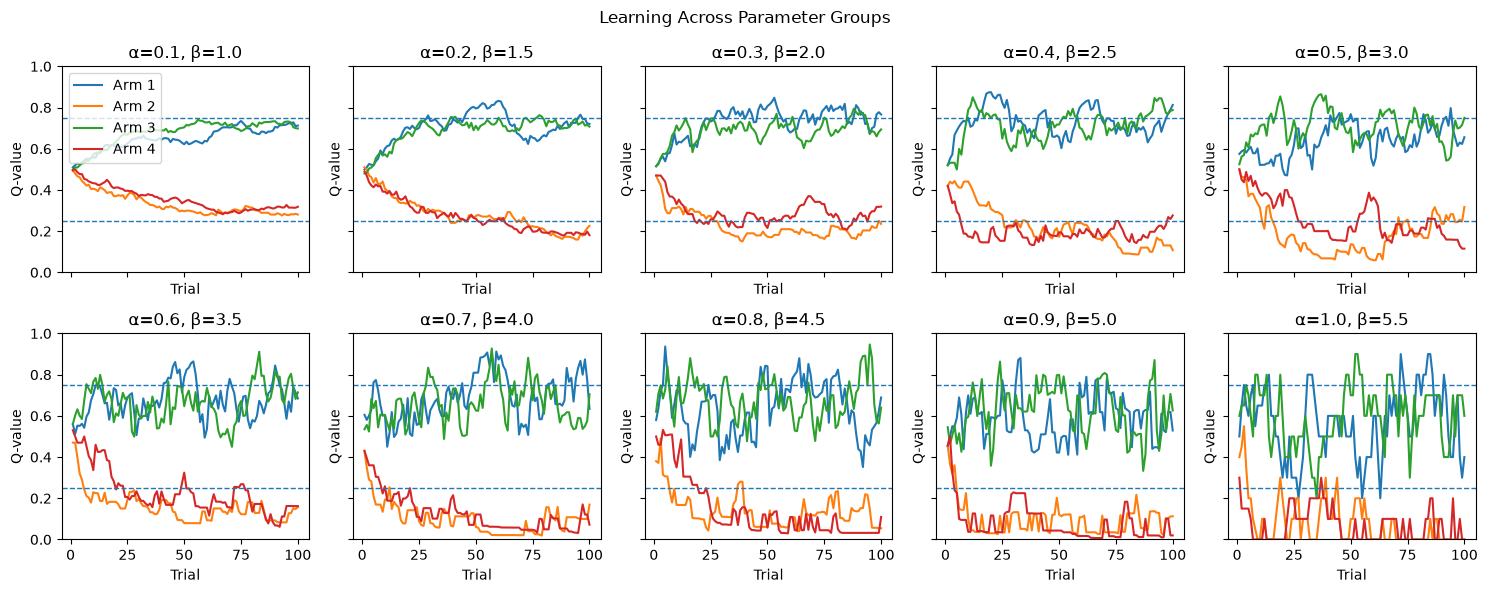

In [ ]:
import random
import csv
import math
import os
import numpy as np
import matplotlib.pyplot as plt


# number of trials and participants
trials_per_participant = 100
trials_per_pair = 50
number_of_agents = 100


# reward probabilities for the arms ine ach bandit
good_arm_win_chance = 0.75
bad_arm_win_chance = 0.25


random.seed(10)


def get_outcome(win_chance):

    if random.random() < win_chance:
        return 1
    else:
        return 0


def get_probability(Q_first, Q_second, beta):

    first = math.exp(beta * Q_first)
    second = math.exp(beta * Q_second)

    return first / (first + second)


def simulate_participant(agent_number, alpha, beta):

    # start each participant at 0.5
    Q_first = 0.5
    Q_second = 0.5
    Q_third = 0.5
    Q_fourth = 0.5

    history = []

    # this randomly interleaves the two bandits 
    trial_pairs = [1] * trials_per_pair + [2] * trials_per_pair
    random.shuffle(trial_pairs)

    for trial in range(trials_per_participant):

        pair = trial_pairs[trial]

        if pair == 1:

            # bandit 1 (arms 1 & 2)
            probability_first = get_probability(Q_first,Q_second, beta)

            if random.random() < probability_first:

                choice = 1

                outcome = get_outcome(good_arm_win_chance)

                prediction_error = outcome - Q_first

                Q_first = Q_first + alpha * prediction_error

            else:

                choice = 2

                outcome = get_outcome( bad_arm_win_chance)

                prediction_error = outcome - Q_second

                Q_second = Q_second + alpha * prediction_error

        else:

            # focuses on second bandit (arms 3 & 4)
            probability_third = get_probability(Q_third,Q_fourth,beta)

            if random.random() < probability_third:

                choice = 3

                outcome = get_outcome(good_arm_win_chance)

                prediction_error = outcome - Q_third

                Q_third = Q_third + alpha * prediction_error

            else:

                choice = 4

                outcome = get_outcome(bad_arm_win_chance)

                prediction_error = outcome - Q_fourth

                Q_fourth = Q_fourth + alpha * prediction_error


        
        history.append({"agent": agent_number,"trial": trial + 1,"pair": pair,"choice": choice,"outcome": "win" if outcome == 1 else "lose","alpha": alpha,"beta": beta,"Q_arm1": round(Q_first, 3),"Q_arm2": round(Q_second, 3),"Q_arm3": round(Q_third, 3),"Q_arm4": round(Q_fourth, 3)})
        return history


# alpha and beta, (chnaging the range for beta could possibly make things different )
alpha_parameters = [0.10, 0.20, 0.30,0.40,0.50,0.60,0.70, 0.80,0.90,1.00]


beta_parameters = [1.0,1.5,2.0,2.5,3.0,3.5,4.0,4.5,5.0,5.5]



history = []


for agent in range(1, number_of_agents + 1):

    # 10 participants in each bin , maybe add more?
    group = (agent - 1) // 10

    alpha = alpha_parameters[group]
    beta = beta_parameters[group]

    participant_history = simulate_participant( agent,alpha,beta)

    history.extend(participant_history)


print("Total participants:", number_of_agents)
print("Total observations:", len(history))
print("Trials per participant:", trials_per_participant)
print("Trials per pair per participant:", trials_per_pair)


# CSV creation
column_names = list(history[0].keys())

file_path = os.path.expanduser("~/simu_learner_100_paired_parameters.csv")


with open(file_path, "w", newline="") as f:

    writer = csv.DictWriter(f,fieldnames=column_names)
    writer.writeheader()
    writer.writerows(history)


print()
print("Saved CSV:", file_path)
print("Total observations saved:", len(history))


# check the first and last rows
print("First trial:", history[0]["trial"])
print("Last trial:", history[-1]["trial"])
print("First participant:", history[0]["agent"])
print("Last participant:", history[-1]["agent"])


# check that each participant has 100 trials
for agent in range(1, number_of_agents + 1):

    agent_history = [row for row in history
        if row["agent"] == agent]

    pair_1_trials = sum(row["pair"] == 1
        for row in agent_history)

    pair_2_trials = sum(row["pair"] == 2
        for row in agent_history)

    if (len(agent_history) != 100
        or pair_1_trials != 50
        or pair_2_trials != 50):
        print("Check participant:", agent)


print("Trial count check complete.")


# -----------------------------
#The code below is for the plots I made
# -----------------------------

# create 2 rows x 5 columns
fig, axes = plt.subplots(2,5,figsize=(15, 6),sharex=True,sharey=True)


for group in range(10):

    start_agent = group * 10 + 1
    end_agent = start_agent + 9

    group_rows = [row for row in history
        if start_agent <= row["agent"] <= end_agent]


    average_arm_1 = []
    average_arm_2 = []
    average_arm_3 = []
    average_arm_4 = []


    for trial in range(1, 101):

        arm_1_values = [row["Q_arm1"]
            for row in group_rows
            if row["trial"] == trial]

        arm_2_values = [row["Q_arm2"]
            for row in group_rows
            if row["trial"] == trial]

        arm_3_values = [row["Q_arm3"]
            for row in group_rows
            if row["trial"] == trial]

        arm_4_values = [row["Q_arm4"]
            for row in group_rows
            if row["trial"] == trial]


        average_arm_1.append(np.mean(arm_1_values))

        average_arm_2.append(np.mean(arm_2_values))

        average_arm_3.append(np.mean(arm_3_values))

        average_arm_4.append(np.mean(arm_4_values))


    alpha = alpha_parameters[group]
    beta = beta_parameters[group]

    ax = axes.flat[group]


    ax.plot(range(1, 101),
        average_arm_1,
        label="Arm 1")

    ax.plot(range(1, 101),
        average_arm_2,
        label="Arm 2")

    ax.plot(range(1, 101),
        average_arm_3,
        label="Arm 3")

    ax.plot(range(1, 101), average_arm_4,label="Arm 4")


    # actual reward probabilities
    ax.axhline(0.75,
        linestyle="--",
        linewidth=1)

    ax.axhline(0.25,linestyle="--",linewidth=1)


    ax.set_title(f"α={alpha}, β={beta}")

    ax.set_ylim(0, 1)

    ax.set_xlabel("Trial")
    ax.set_ylabel("Q-value")



axes.flat[0].legend()


plt.suptitle( "Learning Across Parameter Groups")

plt.tight_layout()

plt.show()